# 04 — Comparação final dos modelos do Fake.Br

Notebook compatível com o repositório [`LeanderHeitor/fakebr-classificacao`](https://github.com/LeanderHeitor/fakebr-classificacao).

**Não treina nenhum classificador** e não requer GPU. Lê `data/split.csv` e todos os arquivos `resultados/predictions_<modelo>.csv` com as colunas `id,y_true,y_pred,score`.

**Antes de começar:** cole ou envie os cinco CSVs de previsão para a pasta `resultados/` do repositório no Colab. Os arquivos devem corresponder à mesma divisão oficial e ao conjunto de teste completo. Em 20/11/2026, o GitHub do grupo ainda não continha esses CSVs.

## 1. Preparação do ambiente

In [1]:
from pathlib import Path
import os, subprocess, shutil, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_score,
                             ConfusionMatrixDisplay)

REPO = Path('/content/fakebr-classificacao')
if not REPO.exists():
    subprocess.run(['git','clone','-q','https://github.com/LeanderHeitor/fakebr-classificacao.git',str(REPO)], check=True)
    print('Repositório clonado no Colab.')
else:
    print('Usando repositório já existente no ambiente (sem sobrescrever arquivos).')
DIR_RESULTADOS=REPO/'resultados'
DIR_RESULTADOS.mkdir(exist_ok=True,parents=True)
SPLIT = REPO/'data'/'split.csv'
assert SPLIT.exists(), 'Não foi encontrado o split.csv oficial do grupo.'
print('Pasta das previsões:',DIR_RESULTADOS)

Repositório clonado no Colab.
Pasta das previsões: /content/fakebr-classificacao/resultados


## 2. Importar previsões (se ainda não estiverem no repositório)

Opcional: rode a próxima célula e selecione os cinco arquivos `predictions_*.csv` exportados pelos grupos. Se eles já estiverem em `resultados/`, não precisa enviar novamente.

**Não envie arquivos com nomes conflitantes de modelos diferentes.**

In [2]:
# Para fazer upload MANUAL, altere para True e execute esta célula.
FAZER_UPLOAD = False
if FAZER_UPLOAD:
    from google.colab import files
    recebidos=files.upload()
    for nome,bytes_do_arquivo in recebidos.items():
        if not re.fullmatch(r'predictions_[a-zA-Z0-9_-]+\.csv',nome):
            print('Ignorado (nome inesperado):',nome);continue
        destino=DIR_RESULTADOS/nome
        if destino.exists():
            raise FileExistsError(f'Já existe {destino}; confira antes de substituir.')
        destino.write_bytes(bytes_do_arquivo)
        print('Adicionado:', destino)

## 3. Auditoria da comparação

O código exige as **mesmas notícias do teste** para todos os modelos. Verifica IDs, rótulos, previsões e scores. Interrompe se um arquivo contém notícias a mais, a menos ou rótulos trocados.

`0 = verdadeira`, `1 = falsa`.

In [3]:
divisao=pd.read_csv(SPLIT)
colunas=['id','rotulo','split']
assert set(colunas).issubset(divisao.columns), 'O split.csv não contém as colunas esperadas.'
teste_oficial=divisao.loc[divisao.split=='teste',['id','rotulo','par','categoria']].copy()
assert teste_oficial.id.is_unique
ids_esperados=set(teste_oficial.id)

esperados={'logreg','svm','nb','bilstm','bertimbau'}
arquivos=sorted(DIR_RESULTADOS.glob('predictions_*.csv'))
nomes={p.stem.removeprefix('predictions_') for p in arquivos}
print('Modelos encontrados:',sorted(nomes))
faltantes=esperados-nomes
if faltantes:
    print('Modelos ainda ausentes:',sorted(faltantes))
    raise FileNotFoundError('Precisamos dos CSVs dos 5 modelos, gerados no teste oficial, para a comparação completa.')
if nomes-esperados:
    print('Incluindo modelos adicionais:',sorted(nomes-esperados))

validados={}
for caminho in arquivos:
    nome=caminho.stem.removeprefix('predictions_')
    pred=pd.read_csv(caminho,dtype={'id':str})
    obrigatorias=['id','y_true','y_pred','score']
    assert set(obrigatorias).issubset(pred.columns), f'{nome}: faltam colunas.'
    assert pred.id.is_unique and pred.id.notna().all(),f'{nome}: IDs ausentes ou duplicados.'
    assert set(pred.id)==ids_esperados, f'{nome}: arquivo não corresponde exatamente ao teste oficial.'
    pred=teste_oficial.merge(pred,on='id',how='left',validate='one_to_one')
    assert pred.y_true.notna().all()
    assert (pred.y_true==pred.rotulo).all(), f'{nome}: y_true diverge de data/split.csv.'
    assert set(pred.y_pred.unique()).issubset({0,1}), f'{nome}: predições não binárias.'
    assert pred.score.notna().all() and pred.score.between(0,1).all(), f'{nome}: scores inválidos.'
    validados[nome]=pred
    print(f'OK {nome:12s}: {len(pred)} notícias, {int((pred.rotulo!=pred.y_pred).sum())} erros')

print('Todas as previsões têm o mesmo conjunto de teste!')

Modelos encontrados: ['bertimbau', 'bilstm', 'logreg', 'nb', 'svm']
OK bertimbau   : 1080 notícias, 5 erros
OK bilstm      : 1080 notícias, 61 erros
OK logreg      : 1080 notícias, 61 erros
OK nb          : 1080 notícias, 109 erros
OK svm         : 1080 notícias, 62 erros
Todas as previsões têm o mesmo conjunto de teste!


## 4. Tabela única de desempenho

Calculamos novamente as mesmas métricas, sem confiar em resultados impressos ou em subconjuntos do Colab. **F1-macro** dá o mesmo peso às duas classes.

In [4]:
linhas=[]
for nome,pred in validados.items():
    y=pred.rotulo.to_numpy()
    p=pred.y_pred.to_numpy()
    linhas.append({'modelo':nome,
                   'abordagem':'Deep Learning' if nome in ('bilstm','bertimbau') else 'Tradicional',
                   'acuracia':accuracy_score(y,p),
                   'precisao_falsa':precision_score(y,p,pos_label=1,zero_division=0),
                   'recall_falsa':recall_score(y,p,pos_label=1,zero_division=0),
                   'f1_falsa':f1_score(y,p,pos_label=1,zero_division=0),
                   'f1_macro':f1_score(y,p,average='macro',zero_division=0),
                   'erros':int((y!=p).sum())})
resumo=pd.DataFrame(linhas).sort_values('f1_macro',ascending=False).reset_index(drop=True)
display(resumo.style.format({c:'{:.4f}' for c in ['acuracia','precisao_falsa','recall_falsa','f1_falsa','f1_macro']}))
resumo.to_csv(DIR_RESULTADOS/'comparacao_final.csv',index=False)
print('Gerado: resultados/comparacao_final.csv')

,modelo,abordagem,acuracia,precisao_falsa,recall_falsa,f1_falsa,f1_macro,erros
0,bertimbau,Deep Learning,0.9954,1.0000,0.9907,0.9953,0.9954,5
1,logreg,Tradicional,0.9435,0.9510,0.9352,0.9430,0.9435,61
2,bilstm,Deep Learning,0.9435,0.9527,0.9333,0.9429,0.9435,61
3,svm,Tradicional,0.9426,0.9527,0.9315,0.9419,0.9426,62
4,nb,Tradicional,0.8991,0.9043,0.8926,0.8984,0.8991,109


Gerado: resultados/comparacao_final.csv


## 5. Gráfico e matrizes de confusão

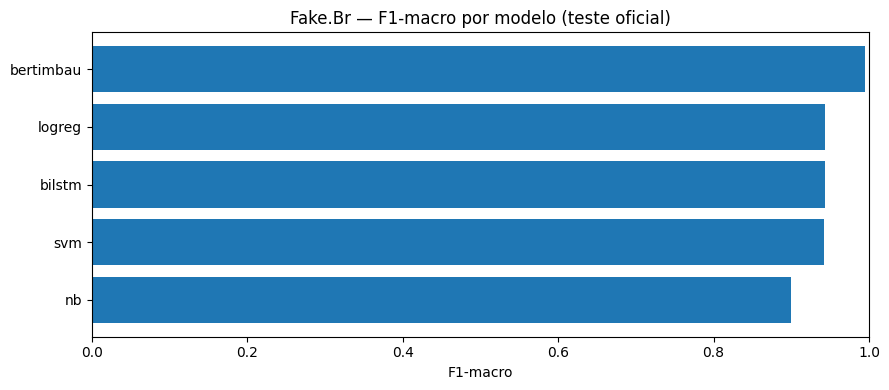

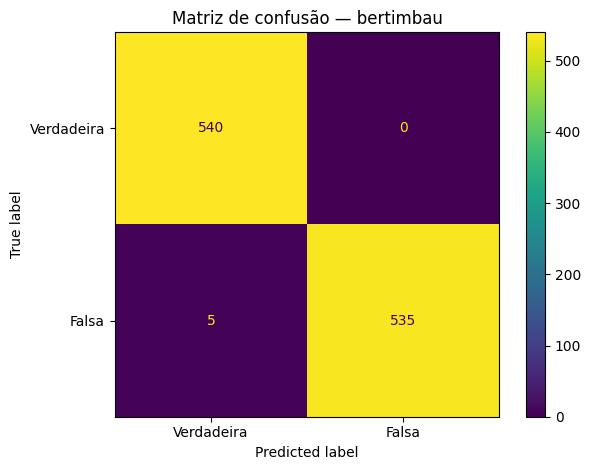

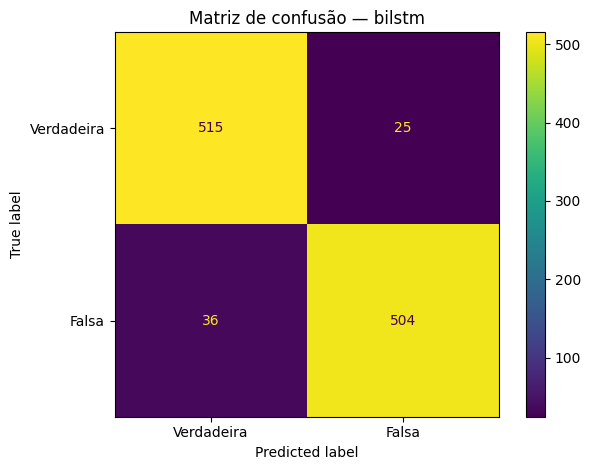

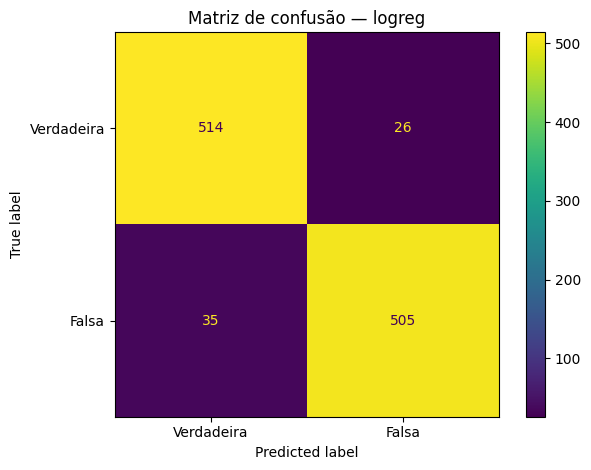

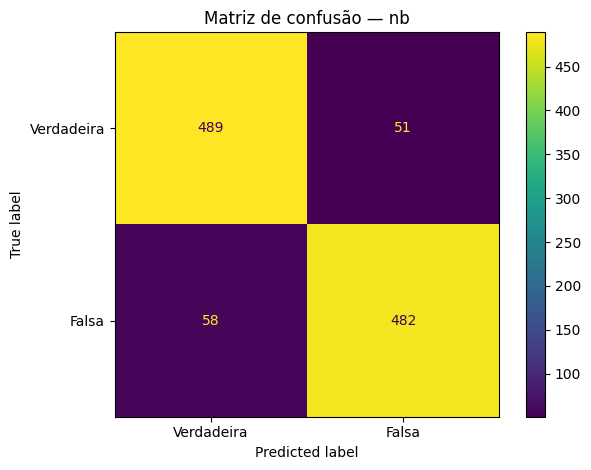

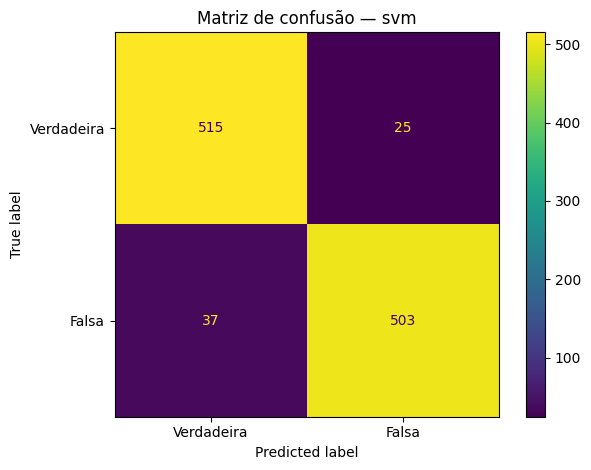

In [5]:
tabela=resumo.sort_values('f1_macro')
plt.figure(figsize=(9,max(4,len(tabela)*0.75)))
plt.barh(tabela.modelo,tabela.f1_macro)
plt.xlim(0,1)
plt.title('Fake.Br — F1-macro por modelo (teste oficial)')
plt.xlabel('F1-macro')
plt.tight_layout()
plt.savefig(DIR_RESULTADOS/'comparacao_f1_macro.png',dpi=160)
plt.show()

for nome,pred in validados.items():
    ConfusionMatrixDisplay.from_predictions(pred.rotulo, pred.y_pred,
        display_labels=['Verdadeira','Falsa'],values_format='d')
    plt.title(f'Matriz de confusão — {nome}')
    plt.tight_layout()
    plt.savefig(DIR_RESULTADOS/f'confusao_{nome}.png',dpi=160)
    plt.show()

## 6. Notícias em que os classificadores discordam

Os IDs abaixo são os identificadores oficiais. O script também destaca notícias que todos os modelos erraram. Para ler o texto integral de cada exemplo, use `from src.dados import carregar_corpus` em uma célula separada.

In [6]:
junta=teste_oficial.copy()
for nome,pred in validados.items():
    junta=junta.merge(pred[['id','y_pred','score']].rename(
        columns={'y_pred':f'pred_{nome}','score':f'score_{nome}'}),on='id',validate='one_to_one')
cols=[f'pred_{nome}' for nome in validados]
junta['quantidade_erros']=junta[cols].ne(junta.rotulo,axis=0).sum(axis=1)
junta['discordam']=junta[cols].nunique(axis=1)>1
casos=junta[junta.discordam].sort_values('quantidade_erros',ascending=False)
display(casos[['id','categoria','rotulo',*cols,'quantidade_erros']].head(20))
print('Discordâncias:',len(casos),'| Erros unânimes:',int((junta.quantidade_erros==len(validados)).sum()))
casos.to_csv(DIR_RESULTADOS/'casos_divergentes.csv',index=False)
junta.to_csv(DIR_RESULTADOS/'previsoes_combinadas.csv',index=False)

,id,categoria,rotulo,pred_bertimbau,pred_bilstm,pred_logreg,pred_nb,pred_svm,quantidade_erros
31,fake_106,politica,1,1,0,0,0,0,4
19,fake_66,politica,1,1,0,0,0,0,4
13,fake_55,politica,1,1,0,0,0,0,4
135,fake_463,politica,1,1,0,0,0,0,4
36,true_161,politica,0,0,1,1,1,1,4
582,true_1997,tv_celebridades,0,0,1,1,1,1,4
465,fake_1552,politica,1,1,0,0,0,0,4
729,fake_2462,politica,1,1,0,0,0,0,4
876,true_2924,politica,0,0,1,1,1,1,4
0,true_6,politica,0,0,1,1,0,1,3


Discordâncias: 171 | Erros unânimes: 1


## 7. Comparação estatística opcional: SVM versus BERTimbau

O teste exato de McNemar compara **os erros em cada mesma notícia**. Por padrão, confrontamos SVM e BERTimbau por serem duas abordagens pré-definidas; não escolhemos os dois melhores com base no teste.

Um p-valor pequeno sugere diferença nos padrões de acerto/erro neste conjunto, mas **não garante generalização para notícias novas**.

In [7]:
from scipy.stats import binomtest
s=validados['svm'][['id','rotulo','y_pred']].rename(columns={'y_pred':'svm'})
b=validados['bertimbau'][['id','y_pred']].rename(columns={'y_pred':'bert'})
pares=s.merge(b,on='id',validate='one_to_one')
ok_svm=pares.svm==pares.rotulo
ok_bert=pares.bert==pares.rotulo
apenas_svm=int((ok_svm & ~ok_bert).sum())
apenas_bert=int((~ok_svm & ok_bert).sum())
discordancias=apenas_svm+apenas_bert
if discordancias:
    pvalor=binomtest(apenas_svm,n=discordancias,p=0.5,alternative='two-sided').pvalue
    print(f'Só SVM acerta: {apenas_svm} | Só BERTimbau acerta: {apenas_bert} | McNemar exato p={pvalor:.4g}')
else:
    print('SVM e BERTimbau têm exatamente os mesmos acertos/erros; não há pares discordantes.')

Só SVM acerta: 4 | Só BERTimbau acerta: 61 | McNemar exato p=3.919e-14


## 8. Para a apresentação e entrega

- Informar que todos usaram o **corpus normalizado por tamanho** e `data/split.csv`.
- Comparar F1-macro, recall da classe falsa, matrizes de confusão e custo de treinamento.
- Apresentar dois exemplos concretos de discordância.
- Reconhecer que o classificador aprende padrões do Fake.Br e **não verifica fatos** autonomamente.
- Não subir os pesos de grandes modelos. Versionar notebooks e CSVs de predições (quando a equipe autorizar).

**O repositório conectado tem permissão de leitura para esta conta.** Para subir diretamente, o responsável precisa conceder permissão de escrita ou receber o conteúdo por Pull Request.